### **We use the existing model for glacier mapping**
All validation scenes are used for validation:

| Model | OA | mIoU | F1-score | Precision | Recall |
|---|---|---|---|---|---|
| patch_256 |  |  |  |  |  |
| patch_1024 | |  |  |  |  |


In [ ]:
import glob
import numpy as np
import pandas as pd
import rasterio as rio
from processing import config
import matplotlib.pyplot as plt
from pyrsimg import imsShow, metrics_segm


In [ ]:
def metric_one(results, truths):
    metrics = []
    for i, (result_arr, truth_arr) in enumerate(zip(results, truths)):
        metrics_sg = metrics_segm(cla_map=result_arr, 
                                truth_map=truth_arr, 
                                class_labels=[0, 1], 
                                mean_mode=True)
        metrics.append({
                    'oa': metrics_sg.oa, 
                    'miou': metrics_sg.iou['labels_mean'],
                    'f1-score': metrics_sg.f1_score['labels_mean'],
                    'precision': metrics_sg.precision['labels_mean'],
                    'recall': metrics_sg.recall['labels_mean']
                    })
    metrics_df = pd.DataFrame(metrics)
    metrics_mean_df = metrics_df[['oa', 'miou', 'f1-score', \
                                  'precision', 'recall']].mean()
    return metrics_df, metrics_mean_df    


In [8]:
paths_val_scene = config.paths_val_scene
paths_val_truth = config.paths_val_truth
# paths_result = sorted(glob.glob('data/result/kang/*'))
# paths_result_ours = sorted(glob.glob('data/result/u3net_cross_fusion/*.tif'))
dirs_result = sorted(glob.glob('data/result/baseline/*'))  
dirs_result = {dir.split('/')[-1]: dir for dir in dirs_result}   
dirs_result['ours'] = 'data/result/val_pred_256'  
print(len(paths_val_scene))  


43


In [4]:
## read data
scenes, truths = [], []
for path_scene, path_truth in zip(paths_val_scene,  paths_val_truth):
    with rio.open(path_scene) as scene_rio:
        scene_arr = scene_rio.read()
        scene_arr = scene_arr.transpose((1, 2, 0))    ## (H,W,C)
        scenes.append(scene_arr)
    with rio.open(path_truth) as truth_rio:
        truth_arr = truth_rio.read()[0]                 ## (H,W)
        profile_truth = truth_rio.profile
        truths.append(truth_arr) 

results = {}
i = 0
for baseline_name, dir_result in dirs_result.items():
    paths_result = sorted(glob.glob(dir_result+'/*.tif'))  
    results[baseline_name] = []
    for path_result in paths_result:
        with rio.open(path_result) as result_rio:
            result_arr = result_rio.read()[0]                 ## (H,W)
            results[baseline_name].append(result_arr)


In [5]:
metrics_df, metrics_mean_df = metric_one(results=results['SegFormer'], truths=truths)   
metrics_mean_df 


oa           0.984295
miou         0.935489
f1-score     0.965231
precision    0.970863
recall       0.960495
dtype: float64

In [6]:
metrics_scences_models = []
metrics_mean_models = []
for key, value in results.items():
    # print('model:', key)
    metrics_scenes, metrics_mean = metric_one(results=results[key], truths=truths)   
    metrics_scenes = {'model': key, **metrics_scenes.miou}
    metrics_mean = {'model': key, **metrics_mean}
    metrics_scences_models.append(metrics_scenes)
    metrics_mean_models.append(metrics_mean)

metrics_mean_df = pd.DataFrame(metrics_mean_models) 
metrics_scences_df = pd.DataFrame(metrics_scences_models).set_index('model')
metrics_scences_df = metrics_scences_df.rename(columns=lambda col: f'scene_{col}' 
                                                        if str(col).isdigit() else col)
metrics_mean_df


,model,oa,miou,f1-score,precision,recall
0,SegFormer,0.984295,0.935489,0.965231,0.970863,0.960495
1,SwinTransformer,0.984898,0.938143,0.966726,0.972002,0.962010
2,Unet,0.985139,0.938039,0.966626,0.972075,0.961899
3,VMambaSegModel,0.985293,0.939667,0.967554,0.970222,0.965459
4,deeplabv3plus_Xception65,0.984473,0.936120,0.965447,0.971832,0.959997
5,hrnet,0.984822,0.938093,0.966656,0.970292,0.963588
6,ours,0.989081,0.951601,0.974308,0.980951,0.968623


model_name: SegFormer, scene_id: 9


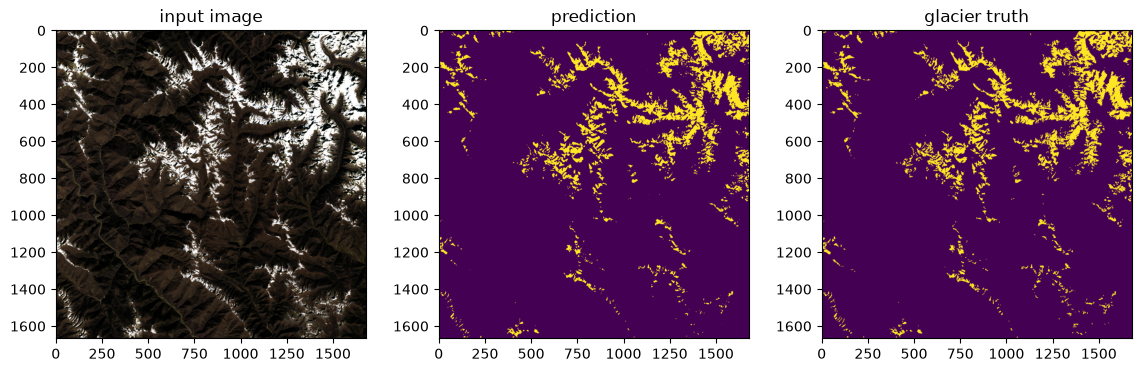

In [7]:
### show the results
i = 9
model_name = 'SegFormer'
print(f'model_name: {model_name}, scene_id: {i}')
imsShow([scenes[i], results[model_name][i], truths[i]], 
        clip_list=[5, 0, 0], 
        img_name_list = ['input image', 'prediction', 'glacier truth'],
        figsize=(14, 4));


### plot accuracy bar

In [8]:
metrics_scences_df

,scene_0,scene_1,scene_2,scene_3,scene_4,scene_5,scene_6,scene_7,scene_8,scene_9,scene_10,scene_11,scene_12
model,,,,,,,,,,,,,
SegFormer,0.922706,0.902002,0.981201,0.923327,0.955044,0.951368,0.868981,0.959196,0.957135,0.851306,0.970804,0.939734,0.978547
SwinTransformer,0.924092,0.900124,0.981925,0.936185,0.958445,0.953620,0.883130,0.949287,0.963413,0.846164,0.971954,0.947888,0.979629
Unet,0.911334,0.900218,0.982549,0.939387,0.958358,0.952541,0.882261,0.962239,0.954178,0.846725,0.972759,0.950658,0.981296
VMambaSegModel,0.918151,0.896947,0.982843,0.941307,0.956483,0.956615,0.881522,0.963601,0.963096,0.850852,0.972339,0.953320,0.978591
deeplabv3plus_Xception65,0.921521,0.899579,0.973863,0.936859,0.951964,0.952034,0.870012,0.962570,0.965063,0.836601,0.971747,0.946786,0.980964
hrnet,0.916652,0.891245,0.980881,0.934474,0.957116,0.953342,0.882736,0.962419,0.965518,0.847789,0.973019,0.949658,0.980355
ours,0.927978,0.918276,0.987541,0.963953,0.971105,0.960728,0.897633,0.975566,0.977494,0.888279,0.977646,0.943503,0.981114


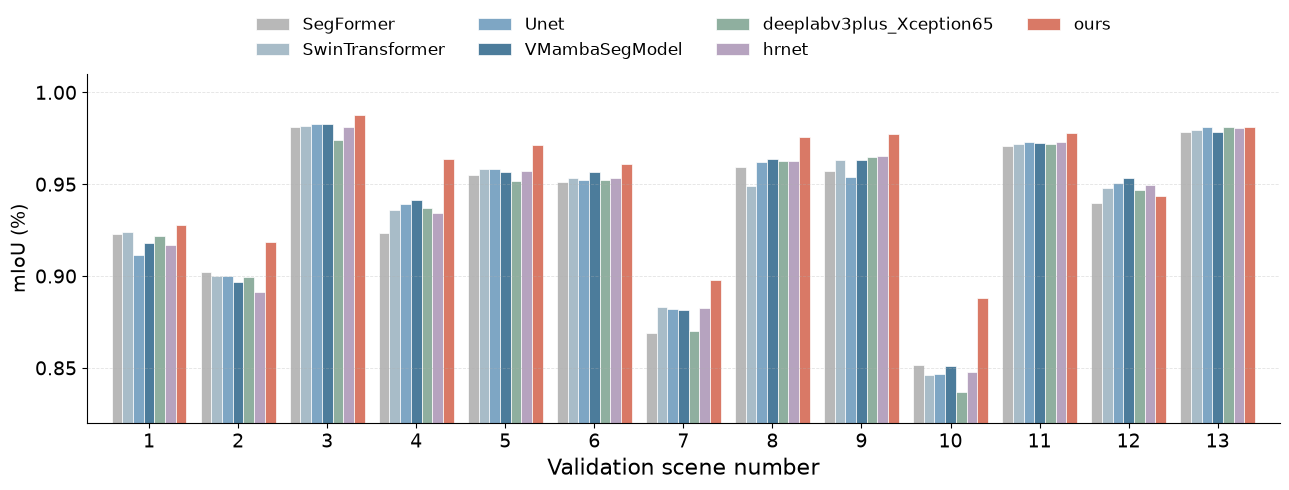

In [12]:
## plot bar chart of mIoU for different satellite scenes by different models
cols = list(metrics_scences_df.index)
labels = list(metrics_scences_df.index)
# colors = ["#B8B8B8", "#7EA6C4", "#4C7C9B", "#D97966"]
colors = ["#B8B8B8", "#A8BCC8", "#7EA6C4", "#4C7C9B", "#8FAF9F", "#B6A3BF", "#D97966"]
# colors = ["#B8B8B8", "#7EA6C4"]

x = np.arange(len(metrics_scences_df.columns))
w = 0.12

fig, ax = plt.subplots(figsize=(13, 5))

for j, (col, label, color) in enumerate(zip(cols, labels, colors)):
    ax.bar(x = x + (j - 3) * w,
        height = metrics_scences_df.loc[col], 
        width=w,
        label=label,
        color=color,
        edgecolor="white",
        linewidth=0.5)

ax.grid(axis="y", linestyle="--", linewidth=0.6, alpha=0.35)

ax.set_xticks(x)
ax.set_xticklabels([f"{i+1}" for i in range(len(metrics_scences_df.columns))])
ax.set_xlabel("Validation scene number", fontsize=16)
ax.set_ylabel("mIoU (%)", fontsize=14)
ax.tick_params(axis='both', labelsize=14)
ax.set_xlim(-0.7, 12.7)
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_linewidth(0.8)

ax.legend(
    ncol=4,
    frameon=False,
    loc="lower center",
    fontsize=12,
    bbox_to_anchor=(0.5, 1))

ax.set_ylim(0.82, 1.01)
ax.set_yticks(np.arange(0.85, 1.01, 0.05))
plt.tight_layout()
plt.show() 


